# 🖼️ 图生图（img2img）

使用同一个本地模型 `stable-diffusion-v1-5`，但管线换成 `StableDiffusionImg2ImgPipeline`。

**与文生图的区别**：文生图从**纯噪声**开始去噪；图生图先把输入图片加噪到一定程度，再从那里开始去噪。

- `strength`（改动强度，0~1）控制加噪程度：
  - 越小 → 越接近原图，变化细微
  - 越大 → 越偏离原图，越接近文生图
- 实际去噪步数 = `num_inference_steps × strength`（如 20 步 × 0.6 = 12 步）

请选择内核：**transformers (15-transformers-basics)**

In [1]:
# 1. 加载图生图管线（与文生图共用同一套模型权重，只加载一次，后续 cell 复用）
import torch
from diffusers import StableDiffusionImg2ImgPipeline

MODEL_DIR = r'S:\PythonAILearningCourse\04-ai-painting-sdxl\stable-diffusion-v1-5'

pipe = StableDiffusionImg2ImgPipeline.from_pretrained(
    MODEL_DIR,
    dtype=torch.float16,   # 半精度：显存减半、速度更快
    variant='fp16',        # 目录里的权重文件名都带 .fp16 后缀，必须指定
)
pipe.to('cuda')
pipe.enable_attention_slicing()    # 降低显存峰值

print('✅ 图生图管线加载完成')

S:\PythonAILearningCourse\15-transformers-basics\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 196/196 [00:00<00:00, 6154.38it/s]

Loading pipeline components...: 100%|██████████| 7/7 [00:00<00:00, 12.75it/s]


✅ 图生图管线加载完成


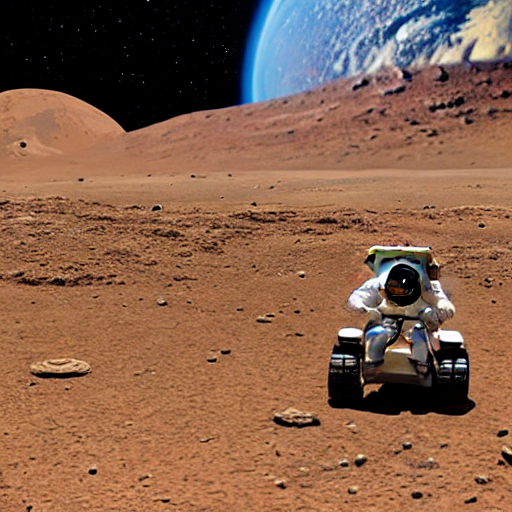

In [2]:
# 2. 载入初始图：换成你自己的图片路径即可（建议缩放到 512×512）
from PIL import Image

INIT_IMG = r'S:\PythonAILearningCourse\04-ai-painting-sdxl\photo\sd_output.png'   # 用 01 笔记本生成的图演示

init_image = Image.open(INIT_IMG).convert('RGB').resize((512, 512))
init_image   # 显示初始图

100%|██████████| 12/12 [00:02<00:00,  5.62it/s]


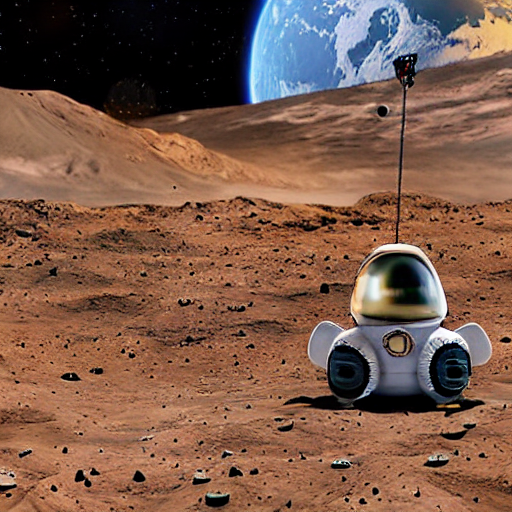

In [3]:
# 3. 图生图：改 prompt / strength 重新运行本 cell，观察对同一张图的不同改写效果
prompt = 'a cute astronaut cat on the moon surface, earth in the sky, digital art, highly detailed'
negative_prompt = 'lowres, bad anatomy, blurry, watermark, text'

image = pipe(
    prompt=prompt,             # 正向提示词：想把它改成什么样
    negative_prompt=negative_prompt,  # 反向提示词：不想出现什么
    image=init_image,          # 初始图（图生图必须传，否则报"incorrect format"）
    strength=0.6,              # 改动强度：0.3~0.5 微调风格，0.6~0.8 大改内容
    num_inference_steps=20,    # 去噪步数（实际执行 20×0.6=12 步）
    guidance_scale=7.5,        # 提示词引导强度
    generator=torch.manual_seed(42),  # 固定种子方便对比不同 strength 的效果
).images[0]

# 保存 + 显示
image.save(r'S:\PythonAILearningCourse\04-ai-painting-sdxl\photo\i2i_output.png')
image